# J'ai deux passions : geographie et manifestations

## Introduction

Les manifestations du 17 octobre ont été d'une ampleur rare en France. L'anticipation de cet évènement était telle que certain&middot;es ont crié à la "fin de l'époque contemporaine". On sait depuis Siegfried (1913) que d'un territoire à l'autre, l'expression politique change du tout au tout, et que les facteurs géographiques sont déterminants dans la politique française.

Une très grande hypothèse de ce projet est la suivante : les manifestant&middot;es, dans leur grande bonté, ont mis à disposition de notre groupe une cartographie exhaustive des évènements du 17 octobre. Tout évènement déclaré a bien eu lieu ; en retour, tout évènement qui a eu lieu a bien été déclaré. La vérification empirique de cette hypothèse demanderait sûrement un scan exhaustif de la presse régionale - si tant est que celle-ci ait rencensé toutes les manifestations — qui dépasse un peu le cadre de ce travail. On assimilera donc ici déclaration d'évènement à évènement. 

Ce mouvement, qui revêtait au départ un aspect très flou, s'est doté de structures d'organisation pour permettre une mobilisation coordonnée (entre les participant&middot;es, et pas par un organe central). Cela fait peut-être suite au mouvement des Gilets Jaunes : la carte que nous avons étudiée permettait d'émettre un signal crédible de la présence de militant&middot;es.

Le but de ce projet est double. 
- D'une part, il s'agit d'obtenir un aperçu, quoique partiel, des déterminants géographiques des évènements du 17 octobre. Quelles sont les prédicteurs, au niveau local, de la présence d'un évènement ? 
- De l'autre, il s'agit de se demander l'échelle la plus pertinente pour analyser ces phénomènes, dans la continuité des interrogations en géographie économique sur le *Modifiable Aeral Unit Problem* (MAUP). Et si l'échelle retenue affectait grandement la performance des prédicteurs trouvés auparavant ? 

Importation des modules:

In [1]:
%pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 82.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 953.1/953.1 kB 70.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 47.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [plotnine]/10 [plotnine]s]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%reload_ext autoreload
%autoreload 2
import pandas as pd
import numpy as np
import folium
import useful.useful_db as udb
import ipywidgets

In [3]:
#pour vérifier quelles fonctions on a :
import importlib
importlib.reload(udb)
print([name for name in dir(udb) if not name.startswith("__")])

['MarkerCluster', 'URL_COMMUNES', 'ajouter_code_insee', 'carte_events', 'carti_download', 'couleur_evenement', 'couleurs_actions', 'desc_bool', 'desc_types_events', 'envoyer_vers_s3', 'folium', 'get_fs', 'gpd', 'ipywidgets', 'merge_communes', 'np', 'pd', 'recuperer_depuis_s3', 'sys']


##  Comment nous avons webscrapé la carte du 17 octobre ###

### Le point de départ

 Nous sommes partis de la carte interactive du site https://17octobregiletjaune.net/carte/ qui répertorie les actions du 17 octobre. Les données sur les actions, y compris le type (manifestation, assemblée, blockage etc.) et leur coordonnées géographiques, sont téléchargées par le JavaScript de la page (une requête vers /api/actions), utilisées pour afficher des "pop-ups", puis nettoyées. 

### La méthode 

Il s'agit de figer le code au bon moment avec des points d'arrêt/ breakpoints. On a cherché les endroits où les données viennent d'être téléchargées ou traitées. Le déclic vient de la fonction qui crée les marqueurs de la carte : Une fois lieux et actions dans la console, il suffit de les copier et les coller dans un fichier csv. 

Pour un tutoriel plus complet : 


Importation des bases :

In [4]:
# table qu'on a scrapée
from bdd.AR_S3 import recuperer_depuis_s3

recuperer_depuis_s3("just17.csv", "/home/onyxia/work/python_manifestation_explosion/bdd/just17.csv")

# table d'appartenance des communes à des zones géographiques
recuperer_depuis_s3("appartenance_commune.xlsx", "/home/onyxia/work/python_manifestation_explosion/bdd/appartenance_commune.xlsx")

'/home/onyxia/work/python_manifestation_explosion/bdd/appartenance_commune.xlsx'

In [5]:
scraped = pd.read_csv("/home/onyxia/work/python_manifestation_explosion/bdd/just17.csv", sep=";")

all_communes = pd.read_excel(
    "/home/onyxia/work/python_manifestation_explosion/bdd/appartenance_commune.xlsx",
    header=5,
    dtype=str,
    engine="calamine",
)


## Aperçu des données

### Valeurs manquantes

Nous avons scrapé ce [site](https://www.17octobregiletjaune.net/carte/17-octobre/), créé par Benjamin Ball, qui permettait à chacun&middot;e de renseigner un point de manifestation pour le 17 octobre, et de se déclarer comme participant&middot;e aux dites manifestations. Ces manifestations sont renseignées dans le fichier `nom de fichier.csv`. Un aperçu rapide de la table donne :

In [6]:
scraped.head(5)
print(f"Cette table contient {len(scraped)} lignes, correspondant à autant d'évènements.")
print(scraped.columns)


Cette table contient 2237 lignes, correspondant à autant d'évènements.
Index(['id', 'title', 'time', 'date', 'amount', 'ville', 'gazole', 'cp', 'maj',
       'nom', 'exploitant', 'adresse', 'lat', 'dep', 'e10', 'annonce', 'heure',
       'commune', 'rondpoint', 'lon', 'genre'],
      dtype='str')


On enlève les sites pour lesquels on n'a pas de coordonnées, qui ne pourront de toute façon pas être utilisées

In [7]:
scraped_cleaned = scraped.dropna(subset=["lat","lon"])
print(f"Il y a {len(scraped_cleaned)} lignes où sont renseignées des coordonnées géographiques.")

scraped_dirty = scraped[scraped["lat"].isna()|scraped["lon"].isna()]
print(f"Il y a {len(scraped_dirty)} lignes où ne sont pas renseignées de coordonnées géographiques.")



Il y a 2009 lignes où sont renseignées des coordonnées géographiques.
Il y a 228 lignes où ne sont pas renseignées de coordonnées géographiques.


Penchons nous de plus près sur ces lignes sans coordonnées :

In [8]:
nb_villes = scraped_dirty["ville"].notna().sum()
print(f"Il y a {nb_villes} lignes où la ville est renseignée.")

Il y a 0 lignes où la ville est renseignée.


Elles nous inquiètent moins désormais : on peut les enlever en toute sécurité.

In [9]:
scraped = scraped_cleaned

### Statistiques et cartes descriptives

Sur le site, les participant&middot;es étaient invité&middot;es à renseigner le type d'évènement qui allait se dérouler. Ces types sont renseigéns dans la colonne `title` :

In [10]:
types_events = scraped["title"].unique().tolist()
types_events_freq = scraped["title"].value_counts(dropna=False)
display(types_events_freq)

title
manifestation         606
rassemblement         434
blocage               291
assemblee             206
rond_point            199
barrage_filtrant      131
operation_escargot     46
autre                  40
pancartes              24
tractage               23
prise_de_parole         6
piquet_de_greve         3
Name: count, dtype: int64

NB: une "opération escargot" correspond à un ralentissement volontaire de la circulation par des automobilistes coordonné&middot;es.

En termes de distribution dans l'espace, voici ce qui apparait :

In [11]:
carte_all_events = udb.carte_events(scraped)
carte_all_events

NB : nous avons choisi de garder les DROM COM dans la plupart de nos cartes, dans un souci d'inclusivité.

Afin de faire des statistiques sur la distribution des évènements en France, on y ajoute le code Insee pour chacune des communes. Pour cela, on essaie de croiser directement avec un fond de carte fourni par etalab à [cette adresse](https://etalab-datasets.geo.data.gouv.fr/contours-administratifs/) :

In [12]:
scraped_insee = udb.ajouter_code_insee(scraped)
print(f"On n'a pas de perte : il y a {len(scraped_insee) - len(scraped)} lignes différentes entre `scraped` et `scraped_insee")

On n'a pas de perte : il y a 0 lignes différentes entre `scraped` et `scraped_insee


On la croise ensuite avec une table avec toutes les communes françaises, fournie par l'Insee.

In [13]:
all_communes_events = udb.merge_communes(scraped_insee, all_communes)
len(all_communes_events)
# ceci permet d'enregistrer cette base de données dans le s3
# from bdd.AR_S3 import envoyer_vers_s3
# all_communes_events.to_csv(
#    "/home/onyxia/work/python_manifestation_explosion/bdd/all_communes_events.csv",
#    sep=";",
#    index=False,
#)
# envoyer_vers_s3("/home/onyxia/work/python_manifestation_explosion/bdd/all_communes_events.csv")

35737

Cela nous permet de faire des statistiques à l'échelle de la France. 

In [14]:
udb.desc_types_events(all_communes_events)

,Effectif,Proportion (%)
Par types d'évènements,,
NaN,33751,94.4
Manifestation,597,1.7
Rassemblement,425,1.2
Blocage,289,0.8
Assemblee,206,0.6
Rond point,198,0.6
Barrage filtrant,129,0.4
Operation escargot,46,0.1
Autre,40,0.1


In [15]:
udb.desc_bool(all_communes_events)

,Effectif,Proportion (%)
has_event,,
Sans événement,33751,96.78
Avec événement,1124,3.22


## Cartographie 
Dans cette partie nous allons générer des cartes qui renvoient un message sur les zones de France où les manifestations sont les plus importantes. Nous commençons par une carte par département où le dégradé de couleur de blanc à rouge suit le nombre de déclaration d'évenemtns par départements. Cette carte est interactive. La carte suivante est statique.  

In [16]:
import sys
sys.path.append("/home/onyxia/work/python_manifestation_explosion/useful")
import chloroplethe_stat_des as chp

# Carte réactive
chp.carte_choroplethe_departements(scraped)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

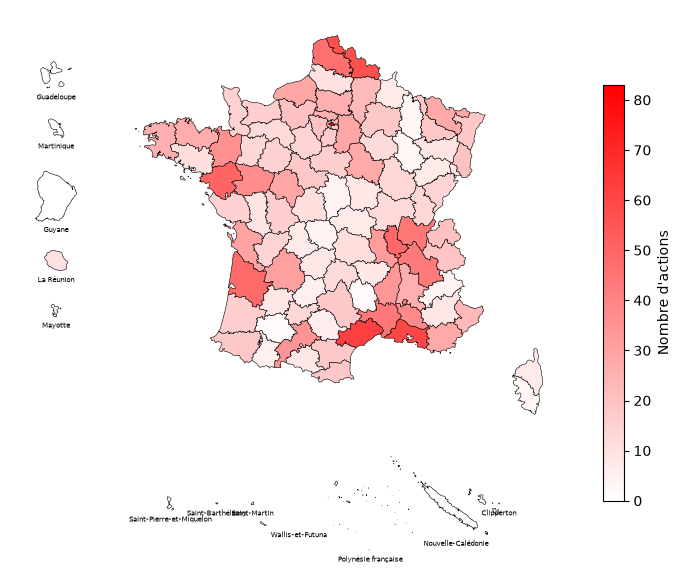

In [17]:
import sys
sys.path.append("/home/onyxia/work/python_manifestation_explosion/useful")
import chloroplethe_stat_des as chp

# Version statique
chp.carte_choroplethe_statique(scraped)

Comme le département n'est pas une unité qui peut donner une impression faussée, nous reproduisons la carte par commune. On remarque qu'effectivement, ce sont les communes les plus importantes en nombre d'habitants qui font que les départements sont de plus en plus rouges.

In [18]:
from carte_colore_commune import carte_choroplethe_interactive

m = carte_choroplethe_interactive(
    scraped,
    niveau="commune",
    uniquement_actifs=True,
)
m

Nous allons donc essayer de contrôler ce fait pour isoler d'autres impacts sociodémographiques en pondérant la colorimétrie par le nombre d'habitants par commune. 

/tmp/ipykernel_256467/1654432538.py:3: DtypeWarning: Columns (0: CODGEO, 2: DEP, 5: EPCI, 7: ARR, 8: CANOV, 10: UU2020, 12: BV2022, 26: dep, 34: code_insee, 36: COM) have mixed types. Specify dtype option on import or set low_memory=False.
  commune_events_pop = pd.read_csv("/home/onyxia/work/python_manifestation_explosion/bdd/commune_events_pop.csv", sep=";")


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

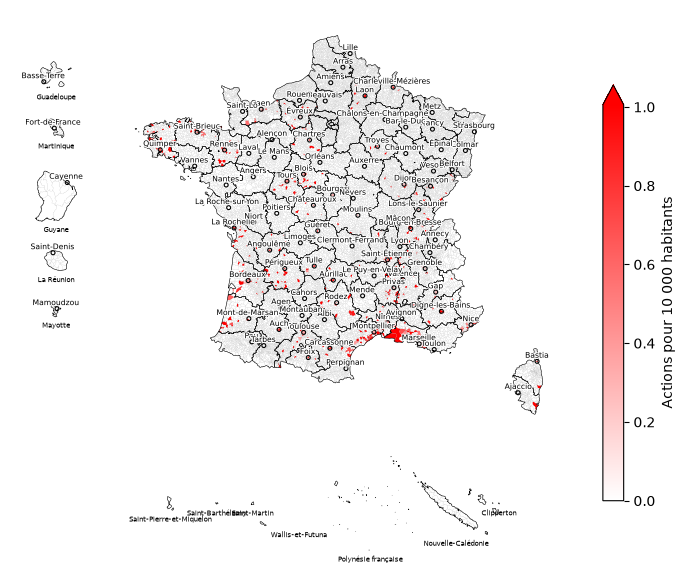

In [19]:
from bdd.AR_S3 import recuperer_depuis_s3
recuperer_depuis_s3("commune_events_pop.csv","/home/onyxia/work/python_manifestation_explosion/bdd/commune_events_pop.csv")
commune_events_pop = pd.read_csv("/home/onyxia/work/python_manifestation_explosion/bdd/commune_events_pop.csv", sep=";")

from carte_colore_commune import preparer_table_ponderee,carte_statique_ponderee
m = carte_statique_ponderee(commune_events_pop,col_pop="PMUN",pop_min=1000)
m

## Impact des variables socio-démographiques

Pour comprendre si les actions du 17 octobre se sont tenues dans des communes avec des caractéristiques socio-démographiques particulières, nous avons d'abord regardé : 

- la **taille** de la commune (nombre d'inscrits, diffère légèrement du nombre d'habitants) ;
- son **niveau d'équipement** : nombre d'équipements de la Base permanente des équipements (Insee) pour 1 000 habitants ;
- son **vote** au 1er tour des législatives 2024 : part de chaque bloc politique et participation.


Les données sont tirées des fichiers suivants (tous disponibles sur le s3)
- `commune_events_pop.csv`, une ligne par commune, avec `has_event` = la commune a-t-elle accueilli un événement ? 
-  `bpe.csv`, Base permanente des équipements (Insee), un équipement par ligne
- `vote.csv`, les résultats du 1er tour des législatives 2024 par commune 
Rmq : Les nuances politiques sont regroupées en cinq blocs : extrême gauche, gauche, droite, extrême droite, divers (qui semble renvoyer avant tout aux candidats régionalistes). On raisonne par blocs pour plus de clarté et car l'offre électorale change d'une circonscription à l'autre
(l'extrême droite est représentée tantôt par un candidat RN, tantôt UXD).

Tout le traitement est dans `explications/poisson.py`. 

In [ ]:
%run explications/poisson.py

Événements : 34,875 communes, dont 1,124 avec un événement


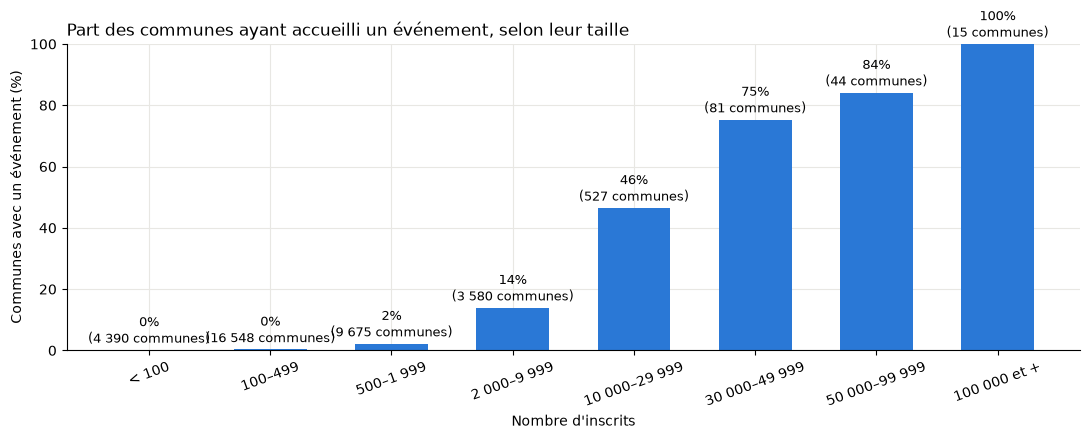

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True})

# Classes de taille (en nombre d'inscrits)
bornes = [0, 100, 500, 2000, 10000, 30000, 50000, 100000, np.inf]
noms = ["< 100", "100–499", "500–1 999", "2 000–9 999", "10 000–29 999",
        "30 000–49 999", "50 000–99 999", "100 000 et +"]
df["classe_taille"] = pd.cut(df["Inscrits"], bornes, labels=noms, right=False)

par_taille = df.groupby("classe_taille", observed=True)["a_eu_action"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(11, 4.5))
barres = ax.bar(par_taille.index.astype(str), par_taille["mean"] * 100, color=BLEU, width=0.6)
for b, (taux, n) in zip(barres, par_taille.itertuples(index=False)):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{taux:.0%}\n({n:,} communes)".replace(",", " "),
            ha="center", va="bottom", fontsize=9)
ax.tick_params(axis ="x", rotation = 20)
ax.set_ylabel("Communes avec un événement (%)")
ax.set_xlabel("Nombre d'inscrits")
ax.set_ylim(0, min(100, par_taille["mean"].max() * 100 * 1.3))
ax.set_title("Part des communes ayant accueilli un événement, selon leur taille", loc="left")
plt.tight_layout()
plt.show()

La probabilité d'accueillir un événement augmente très fortement avec la taille de la commune.
Or la taille est aussi liée au vote (les grandes communes votent davantage à gauche, les petites
davantage à l'extrême droite et participent plus) et aux équipements présents. **Toute comparaison entre communes doit donc
se faire à taille égale**, sinon on attribue au vote ou aux mauvais/bon équipement ce qui relève de la taille.

**Le modèle de régression**

On explique le fait d'avoir accueilli un événement (0 ou 1) par une régression de Poisson
avec erreurs-types robustes, groupées par département (« Poisson modifié »). Cette méthode donne
directement des **rapports de probabilités** :

$$\text{effet en \%} = \left(e^{\hat\beta} - 1\right) \times 100$$

se lit « la probabilité d'avoir accueilli un événement est X % plus élevée ».

**Lecture des variables.**
- Vote et participation : effet de **+10 points**. Les parts des blocs somment à 100 %, la **droite** sert de
  référence : « +10 points pour ce bloc, pris à la droite ».
- Équipement : effet d'**un écart-type** de plus (log des équipements pour 1 000 inscrits, standardisé).
- Taille : `log_inscrits`, effet pour une commune 2,7 fois plus grande.

**Trois modèles**, de plus en plus exigeants :
(1) vote + taille ; (2) + participation et équipement ; (3) + effets fixes département,
c'est-à-dire qu'on ne compare que des communes **d'un même département**.

In [25]:
print("\n" + "=" * 90)
print("Variation de la probabilité d'avoir eu un événement (en %)")
print("  vote et participation : pour +10 points | équipement : pour +1 écart-type")
print("  log_inscrits : pour une commune 2,7 fois plus grande | bloc de référence : droite")
print("=" * 90)
print(effets.round(1).to_string())
print("\np-values (< 0,05 : effet significatif au seuil de 5 %)")
print(pvalues.round(3).to_string())
print(f"\nModèle (3) : {(~dep_avec_evenement).sum():,} communes retirées "
      f"(départements sans aucun événement)")



Variation de la probabilité d'avoir eu un événement (en %)
  vote et participation : pour +10 points | équipement : pour +1 écart-type
  log_inscrits : pour une commune 2,7 fois plus grande | bloc de référence : droite
                       (1) vote + taille  (2) + participation et équipements  (3) + effets fixes département
pct_extreme_gauche_10              171.1                               109.7                            66.2
pct_gauche_10                        1.4                                -3.9                            -2.0
pct_extreme_droite_10               14.4                                10.7                            18.0
pct_divers_10                      -15.8                               -30.3                            -6.3
participation_10                     NaN                               -19.1                           -32.6
equipement_z                         NaN                                98.3                           107.1
log_inscrits     

**Quelques résultats**

- **La taille** : plus une commune est grande, plus elle a de chances d'avoir accueilli un événement
- **L'équipement** : A taille égale et au sein du même département, une commune nettement mieux équipée (écart-type +1) a environ 2 fois plus de chances d'avoir connu au moins un événement le 17 octobre. Il semble cohérent aveec le fait que les événements se tiennent dans les pôles locaux, mieux équipés en termes de commerces, écoles, hôpitaux etc.,  qui rassemblent aussi les habitants des communes voisines. 
- **Le vote** : Le lien entre vote à gauche et événement disparaît dès qu'on contrôle la taille de la commune. Les effets extrême gauche et bloc divers disparaissent également lorsqu'on se place à l'échelle d'un même département (pas significatifs). Le vote à l'extrême droite au sein d'une commune est corrélé positivement au fait qu'une action aie eu lieu (un résultat qu'on ne s'explique pas). Autre effet surprenant : une participation électorale plus forte au sein d'une commune s'accompagne d'une probabilité d'événement plus faible. 

Limite : Ce sont des **corrélation** entre communes qui ne disent pas qui ne dit rien de l'effet causal, ni de qui a participé aux événements

## Quelle échelle ?

Le MAUP est un problème qui se pose en premier lieu à celui ou celle qui tente de donner des explications aux phénomènes géographiques. Il est prouvé depuis que l'échelle de l'analyse change les résultats, et ce de deux manières (Briant et al., 2010) : 
- l'agglomération des zones, c'est-à-dire leur regroupement en des ensembles plus ou moins grans, change la donne (de la commune, au département, à la région)
- la forme des zones, c'est-à-dire le découpage de ces zones (commune VS zone d'emploi)

Schématiquement, cela donne : 

![Fig 1 : Briant et al., 2010](modele_echelle/MAUP_simple.png)

Nous allons ici essayer de comparer les performances des modèles prédictifs, en fonction des découpages géographiques choisis.

Pour chaque niveau d'agrégation $k$ (par exemple commune, département, région) et chaque unité $i$, on note $Y_i$ le nombre de manifestations (`nb_events`), $P_i$ la population et $x_i$ le prix de l'essence, en centimes. Comme $Y_i$ est un comptage, on estime une régression de Poisson avec lien logarithmique, selon deux spécifications de la moyenne conditionnelle :

1. **Modèle avec offset** ($\gamma = 1$ imposé, modèle de taux par habitant) :
$$\ln \mathbb{E}[Y_i \mid x_i, P_i] = \ln P_i + \beta_0 + \beta_1 x_i$$

2. **Modèle avec $\ln P_i$ libre** ($\gamma$ estimé) :
$$\ln \mathbb{E}[Y_i \mid x_i, P_i] = \beta_0 + \beta_1 x_i + \gamma \ln P_i$$

Ces modèles sont particulièrement adaptés au MAUP, car le paramètre $\gamma$ renseigne directement sur **la façon dont le nombre de manifestations évolue avec la taille des unités**. Si la proportionnalité à la population ($\gamma = 1$) tient à une échelle mais pas à une autre, le modèle avec offset est mal spécifié à cette échelle, et $\hat\beta_1$ peut être biaisé. On compare donc, pour chaque niveau d'agrégation, $\hat\beta_1$ (via $e^{\hat\beta_1}$), $\hat\gamma$ et le test de $H_0 : \gamma = 1$. La stabilité de $\hat\beta_1$ entre échelles et entre spécifications est notre indicateur de robustesse au MAUP.

L'estimation se fait par pseudo-maximum de vraisemblance de Poisson, convergent dès que la moyenne conditionnelle est bien spécifiée, avec des écarts-types robustes (HC3). Pour tester l'**effet de zonage**, on peut en outre répéter l'estimation sur des découpages alternatifs de même échelle (par exemple des regroupements aléatoires de communes en unités de taille comparable) et observer la dispersion de $\hat\beta_1$.

**Limites.** Les coefficients sont des associations conditionnelles et non des effets causaux (que sont dans les cours des prochaines semaines en économétrie). Les écarts-types ne sont pas directement comparables d'une échelle à l'autre, puisque le nombre d'unités change (et avec lui la puissance des tests). Enfin, l'indépendance entre unités est une hypothèse discutable, d'autant plus que les unités sont petites et voisines.

In [22]:
import modele_echelle.preprocessing as pp
import statsmodels.formula.api as smf
import statsmodels.formula as sm

SyntaxError: parameter without a default follows parameter with a default (preprocessing.py, line 10)

### Par taille de la zone

Intéressons-nous d'abord à la taille de la zone retenue. On peut ici faire des `group_by` à différentes échelles, pour voir les effets des agglomérations. Pour effectuer nos régressions, on utilise des modèles de Poisson, qui permettent de modéliser les comptages. 

On le fait donc au niveau du département, en préparant d'abord la table de notre échantillon :

In [ ]:
table_dep = pp.table_reg_essence_prix(all_communes_events, 'DEP').dropna().sort_values(by="nb_events")
display(table_dep.head(10))

,nb_events,prix moyen
DEP,,
05,4,231.400000
65,5,221.900000
08,7,233.300000
03,7,232.550000
09,8,227.900000
58,8,226.825000
43,8,223.400000
04,8,226.733333
79,9,222.400000


Il semble que l'on n'ait pas de données renseignées sur le site quant aux prix de l'essence dans les DROM COM. 

Maintenant, pour la région :

In [ ]:
table_region = pp.table_reg_essence_prix(all_communes_events, 'REG').dropna().sort_values(by="nb_events")
display(table_region.head(10))


,nb_events,prix moyen
REG,,
28,91,222.904286
24,92,225.748016
53,99,222.047078
27,104,228.710714
52,130,223.257340
44,136,229.530208
93,161,224.718531
32,163,222.402245
75,209,225.766886


On fait maintenant des régressions linéaires en utilisant `statsmodels` :

### Par forme de la zone